In [26]:
## load packages and read data ##
import pickle 
import cmdstanpy
import pandas as pd
import numpy as np
import arviz as az
from scipy.special import logit
import os
from os import listdir
from os.path import isfile, join
import scripts.helper_functions as func

# paths
dataset = 'exp1'
clean_path = '~/code/ast_human/data/clean/' + dataset + '/'
fits_path = os.path.expanduser('~/code/ast_human/model_fits/' + dataset + '/safrl/stan/')

# load data
data = pd.read_csv(clean_path + 'clean_data.csv')
data_dict = func.make_stan_datalist(data, save_trials=0)

# load fits
models = [f for f in listdir(fits_path) if isfile(join(fits_path, f))]

fits = []
for model in models:
    with open(fits_path + model, 'rb') as f:
        fits.append(pickle.load(f))

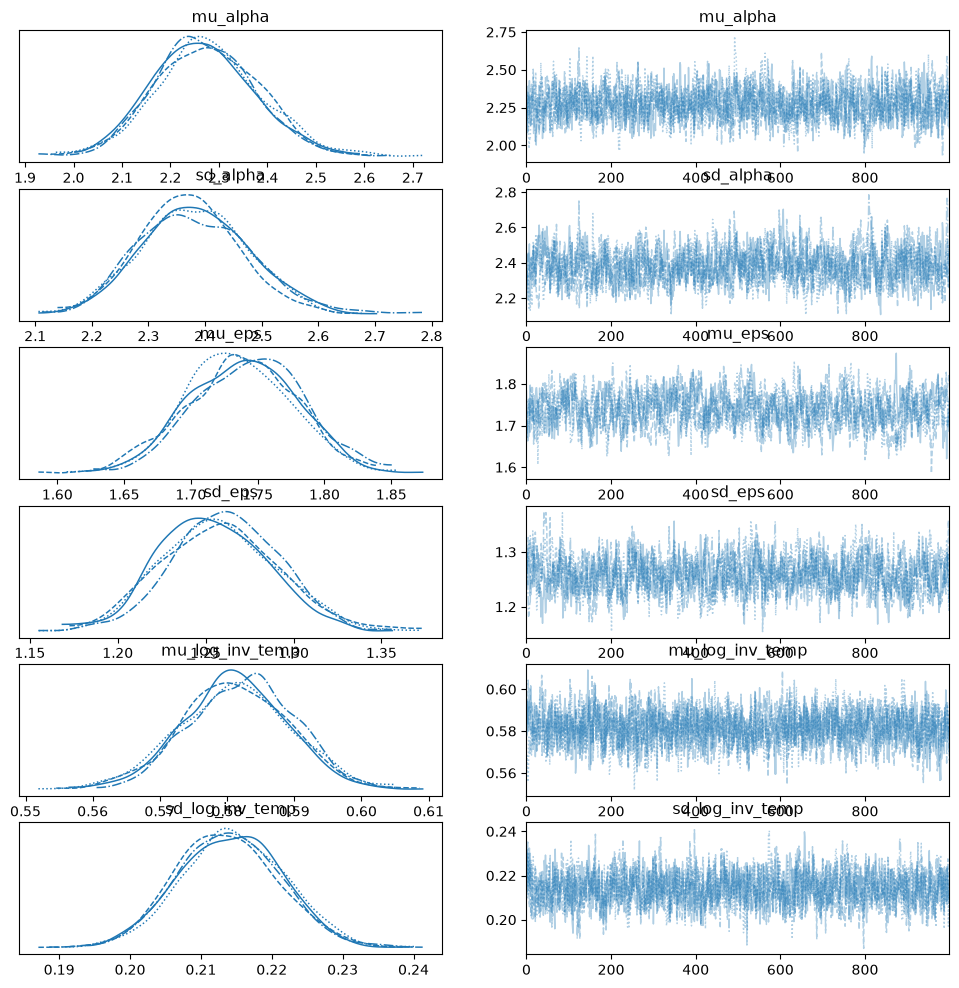

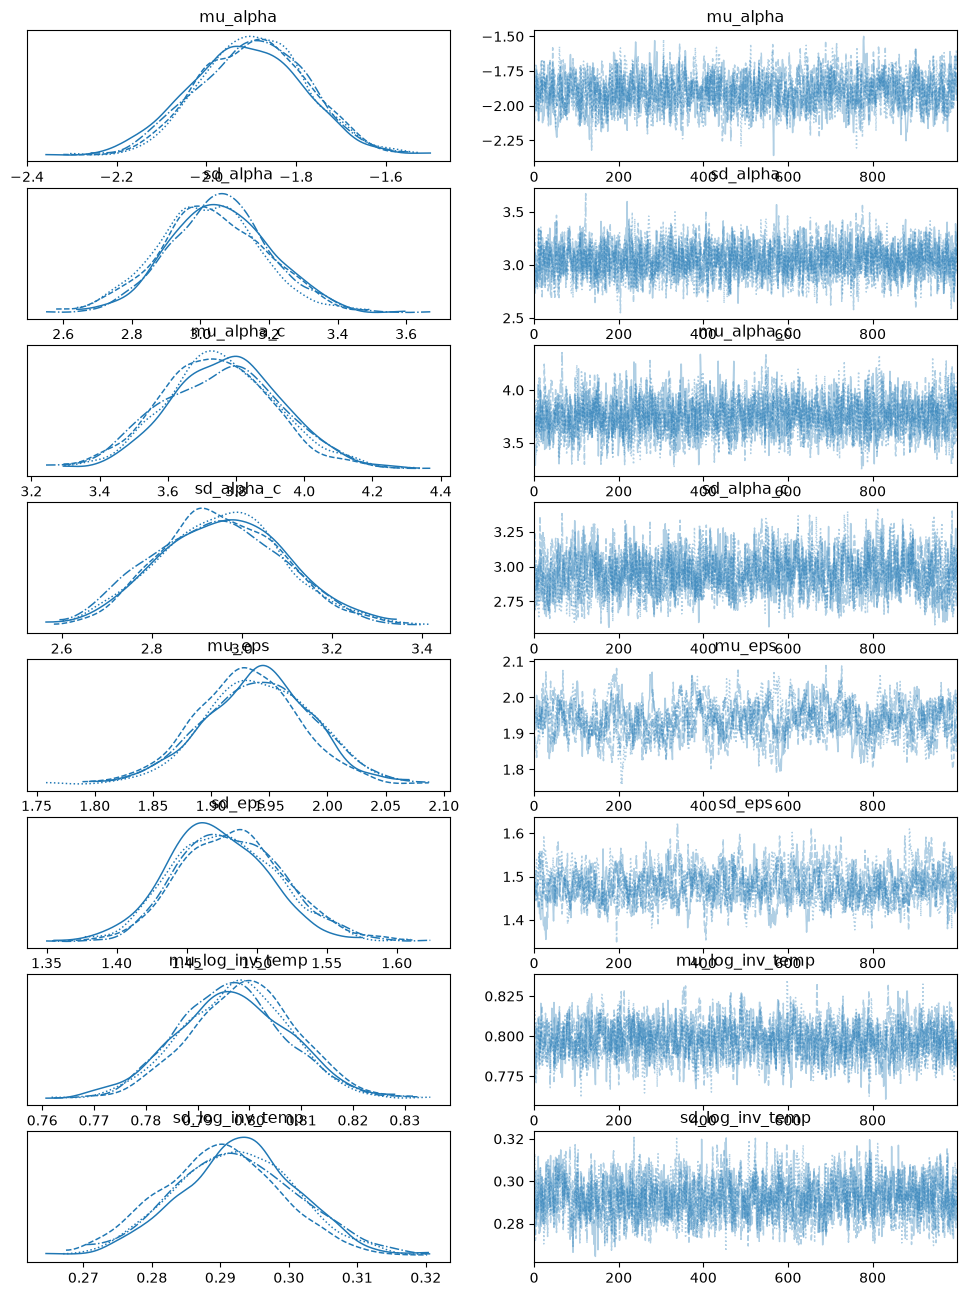

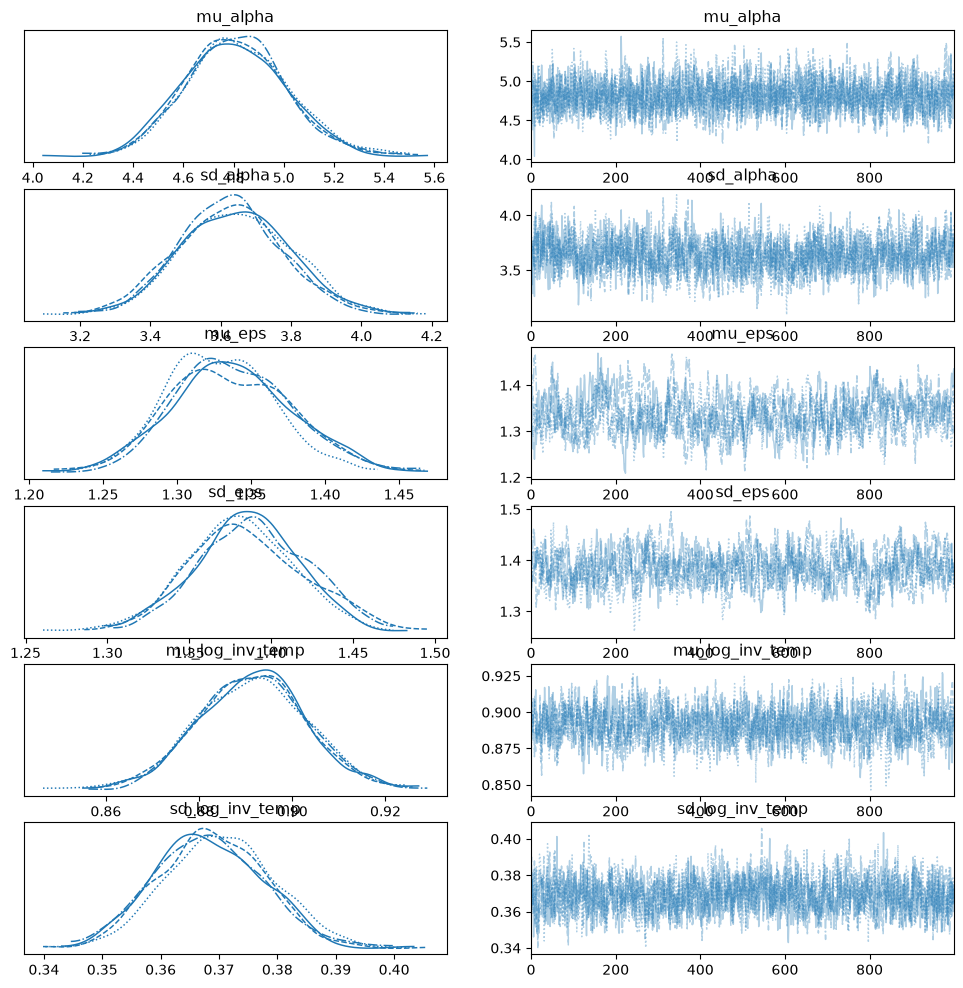

In [27]:
## check diagnostics ##
# plot trace of group level parameters

for i in range(len(fits)):
    fit = fits[i]
    var_labels = [x for x in fit.stan_variables().keys() if x.startswith(('mu', 'sd'))]

    # convert fit to InferenceData
    idata = az.from_cmdstanpy(fit)

    # trace plot for specific parameters
    az.plot_trace(idata, var_names=var_labels)

In [28]:
idata_dict = {
    model: az.from_cmdstanpy(
        posterior=fit,
        log_likelihood={"choice": "subj_log_lik"}
    )
    for model, fit in zip(models, fits)

}
loos = {name: az.loo(idata) for name, idata in idata_dict.items()}

comparison = az.compare(
    idata_dict,
    ic="loo",
)

print(comparison)

/home/rowan/code/ast_human/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/rowan/code/ast_human/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/home/rowan/code/ast_human/.venv/lib/pytho

                           rank      elpd_loo        p_loo    elpd_diff  \
safrlC alphaC.pkl             0 -76402.249705  3047.137670     0.000000   
safrlC counterfactual.pkl     1 -79966.078317  2289.309681  3563.828612   
safrl.pkl                     2 -84977.836822  2339.386833  8575.587116   

                             weight          se         dse  warning scale  
safrlC alphaC.pkl          0.931366  935.513979    0.000000     True   log  
safrlC counterfactual.pkl  0.053613  975.942335  198.247274     True   log  
safrl.pkl                  0.015021  931.518864  176.892503     True   log  


/home/rowan/code/ast_human/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


In [29]:
models

['safrlC counterfactual.pkl', 'safrlC alphaC.pkl', 'safrl.pkl']

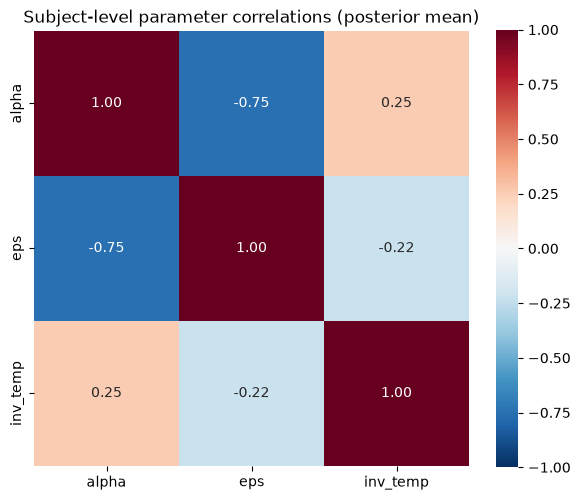

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
tmp_fit = fits[0]
# Extract posterior means for each subject-level parameter
params = {
    "alpha":      tmp_fit.stan_variable("alpha_raw").mean(axis=0),       # [N]
    #"alpha_c":      tmp_fit.stan_variable("alpha_c_raw").mean(axis=0),       # [N]
    "eps":        tmp_fit.stan_variable("eps_raw").mean(axis=0),         # [N]
    "inv_temp":   tmp_fit.stan_variable("log_inv_temp_raw").mean(axis=0),    # [N]
    #"theta0":     tmp_fit.stan_variable("init_theta").mean(axis=0),      # [N]
}

df = pd.DataFrame(params)

corr = df.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1, vmax=1,
    square=True,
    ax=ax
)
ax.set_title("Subject-level parameter correlations (posterior mean)")
plt.tight_layout()
#plt.savefig('plots/Sa-FRL-C-4 corr.svg', format='svg')
plt.show()

(array([[<Axes: title={'center': 'alpha'}>,
         <Axes: title={'center': 'alpha'}>],
        [<Axes: title={'center': 'inv_temp'}>,
         <Axes: title={'center': 'inv_temp'}>],
        [<Axes: title={'center': 'eps'}>, <Axes: title={'center': 'eps'}>]],
       dtype=object),)

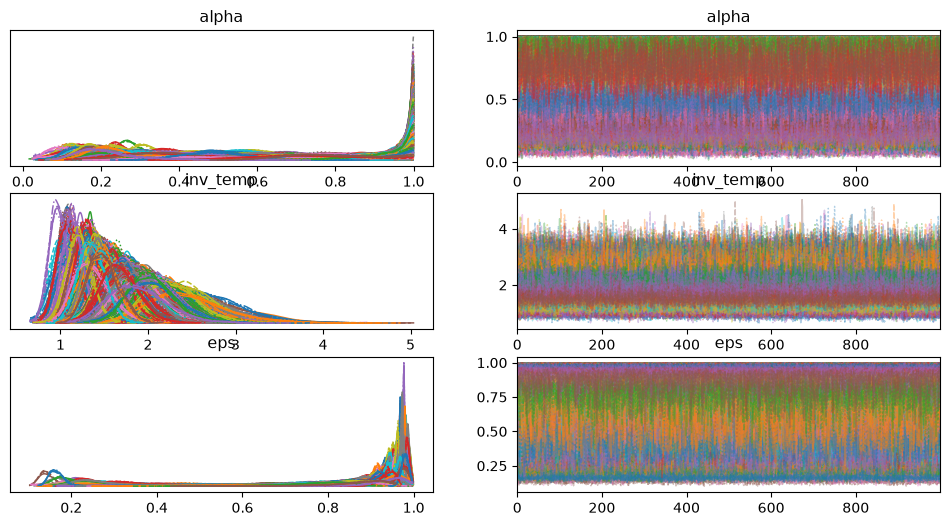

In [34]:
# trace plot for specific parameters
idata = az.from_cmdstanpy(fits[0])
az.plot_trace(idata, var_names=['alpha', 'inv_temp', 'eps']),